In [1]:
# ==========================================
# Projeto de Banco de Dados - Imobiliária (Versão Otimizada e Incrementada)
# ==========================================

import sqlite3
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Função para criar e estruturar o Banco de Dados
def inicializar_banco(nome_db='imobiliaria_pro.db'):
    conn = sqlite3.connect(nome_db)
    cursor = conn.cursor()

    # Habilitar restrições de chave estrangeira
    cursor.execute("PRAGMA foreign_keys = ON;")

    # Criação do Esquema Relacional (DDL)
    cursor.executescript("""
        DROP TABLE IF EXISTS Visita;
        DROP TABLE IF EXISTS Venda;
        DROP TABLE IF EXISTS Compra_do;
        DROP TABLE IF EXISTS Contrata_o;
        DROP TABLE IF EXISTS Imovel;
        DROP TABLE IF EXISTS Corretor;
        DROP TABLE IF EXISTS Proprietario;
        DROP TABLE IF EXISTS Cliente;

        CREATE TABLE Cliente (
            cpf TEXT PRIMARY KEY,
            nome TEXT NOT NULL,
            telefone TEXT NOT NULL
        );

        CREATE TABLE Proprietario (
            cpf TEXT PRIMARY KEY,
            nome TEXT NOT NULL,
            telefone TEXT NOT NULL
        );

        CREATE TABLE Corretor (
            creci TEXT PRIMARY KEY,
            nome TEXT NOT NULL,
            telefone TEXT NOT NULL,
            avaliador INTEGER NOT NULL CHECK (avaliador IN (0, 1))
        );

        -- Imóvel com controle de status integrado
        CREATE TABLE Imovel (
            id_imovel INTEGER PRIMARY KEY AUTOINCREMENT,
            tipo TEXT NOT NULL CHECK (tipo IN ('Casa', 'Apartamento', 'Escritório', 'Comércio')),
            status TEXT NOT NULL DEFAULT 'Disponível' CHECK (status IN ('Disponível', 'Reservado', 'Vendido')),
            rua TEXT NOT NULL,
            numero INTEGER NOT NULL,
            bairro TEXT NOT NULL,
            cidade TEXT NOT NULL,
            cep TEXT NOT NULL,
            preco REAL NOT NULL,
            cpf_proprietario TEXT NOT NULL,
            FOREIGN KEY (cpf_proprietario) REFERENCES Proprietario(cpf) ON DELETE CASCADE ON UPDATE CASCADE
        );

        CREATE TABLE Contrata_o (
            cpf_proprietario TEXT NOT NULL,
            creci_corretor TEXT NOT NULL,
            PRIMARY KEY (cpf_proprietario, creci_corretor),
            FOREIGN KEY (cpf_proprietario) REFERENCES Proprietario(cpf) ON DELETE CASCADE ON UPDATE CASCADE,
            FOREIGN KEY (creci_corretor) REFERENCES Corretor(creci) ON DELETE CASCADE ON UPDATE CASCADE
        );

        CREATE TABLE Compra_do (
            cpf_cliente TEXT NOT NULL,
            creci_corretor TEXT NOT NULL,
            PRIMARY KEY (cpf_cliente, creci_corretor),
            FOREIGN KEY (cpf_cliente) REFERENCES Cliente(cpf) ON DELETE CASCADE ON UPDATE CASCADE,
            FOREIGN KEY (creci_corretor) REFERENCES Corretor(creci) ON DELETE CASCADE ON UPDATE CASCADE
        );

        -- Nova Tabela: Registro de Visitas a Imóveis
        CREATE TABLE Visita (
            id_visita INTEGER PRIMARY KEY AUTOINCREMENT,
            id_imovel INTEGER NOT NULL,
            cpf_cliente TEXT NOT NULL,
            creci_corretor TEXT NOT NULL,
            data_visita TEXT NOT NULL,
            feedback TEXT,
            FOREIGN KEY (id_imovel) REFERENCES Imovel(id_imovel) ON DELETE CASCADE,
            FOREIGN KEY (cpf_cliente) REFERENCES Cliente(cpf) ON DELETE CASCADE,
            FOREIGN KEY (creci_corretor) REFERENCES Corretor(creci) ON DELETE CASCADE
        );

        -- Tabela de Vendas com atributo derivado (comissão)
        CREATE TABLE Venda (
            id_venda INTEGER PRIMARY KEY AUTOINCREMENT,
            id_imovel INTEGER UNIQUE NOT NULL,
            cpf_cliente TEXT NOT NULL,
            creci_corretor TEXT NOT NULL,
            valor_venda REAL NOT NULL,
            percentual_comissao REAL NOT NULL DEFAULT 5.0,
            comissao REAL GENERATED ALWAYS AS (valor_venda * percentual_comissao / 100.0) STORED,
            FOREIGN KEY (id_imovel) REFERENCES Imovel(id_imovel) ON DELETE RESTRICT ON UPDATE CASCADE,
            FOREIGN KEY (cpf_cliente) REFERENCES Cliente(cpf) ON DELETE RESTRICT ON UPDATE CASCADE,
            FOREIGN KEY (creci_corretor) REFERENCES Corretor(creci) ON DELETE RESTRICT ON UPDATE CASCADE
        );
    """)

    conn.commit()
    conn.close()
    print("Banco de dados criado com sucesso!")

# 2. Função para Povoar o Banco com Dados Iniciais
def popular_banco(nome_db='imobiliaria_pro.db'):
    conn = sqlite3.connect(nome_db)
    cursor = conn.cursor()

    cursor.executescript("""
        INSERT INTO Cliente (cpf, nome, telefone) VALUES
        ('111.111.111-11', 'Daniel Luz', '(84) 99999-1111'),
        ('222.222.222-22', 'Maria Souza', '(84) 98888-2222'),
        ('555.555.555-55', 'Beatriz Medeiros', '(84) 99111-2233');

        INSERT INTO Proprietario (cpf, nome, telefone) VALUES
        ('333.333.333-33', 'Luiz Feliciano', '(84) 97777-3333'),
        ('444.444.444-44', 'Klyfithon Paulo', '(84) 96666-4444');

        INSERT INTO Corretor (creci, nome, telefone, avaliador) VALUES
        ('CRECI-1234', 'Carlos Eduardo', '(84) 95555-5555', 1),
        ('CRECI-5678', 'Fernanda Lima', '(84) 94444-4444', 0);

        INSERT INTO Imovel (tipo, status, rua, numero, bairro, cidade, cep, preco, cpf_proprietario) VALUES
        ('Apartamento', 'Vendido', 'Av. Roberto Freire', 1000, 'Ponta Negra', 'Natal', '59090-000', 350000.00, '333.333.333-33'),
        ('Casa', 'Disponível', 'Rua das Dunas', 150, 'Capim Macio', 'Natal', '59078-000', 500000.00, '444.444.444-44'),
        ('Comércio', 'Disponível', 'Av. Afonso Pena', 400, 'Tirol', 'Natal', '59020-100', 750000.00, '333.333.333-33');

        INSERT INTO Visita (id_imovel, cpf_cliente, creci_corretor, data_visita, feedback) VALUES
        (2, '111.111.111-11', 'CRECI-1234', '2026-10-25', 'Cliente demonstrou grande interesse na localização.');

        INSERT INTO Venda (id_imovel, cpf_cliente, creci_corretor, valor_venda, percentual_comissao) VALUES
        (1, '111.111.111-11', 'CRECI-1234', 340000.00, 5.0);
    """)

    conn.commit()
    conn.close()
    print("Dados inseridos com sucesso!")

# Executar a criação e o povoamento
inicializar_banco()
popular_banco()

Banco de dados criado com sucesso!
Dados inseridos com sucesso!


In [2]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import sqlite3
import pandas as pd

# Função auxiliar para buscar listas (ex: proprietários e corretores cadastrados para os selects)
def obter_opcoes_banco(query, coluna):
    try:
        conn = sqlite3.connect('imobiliaria_pro.db')
        cursor = conn.cursor()
        cursor.execute(query)
        resultados = [row[0] for row in cursor.fetchall()]
        conn.close()
        return resultados if resultados else ["Nenhum cadastrado"]
    except:
        return ["Nenhum cadastrado"]

print("=== PAINEL INTERATIVO DE CADASTRO - IMOBILIÁRIA ===")

# ==========================================
# 1. ABA DE CADASTRO DE CLIENTE
# ==========================================
cli_cpf = widgets.Text(description='CPF:', placeholder='000.000.000-00')
cli_nome = widgets.Text(description='Nome:', placeholder='Nome completo')
cli_tel = widgets.Text(description='Telefone:', placeholder='(84) 9XXXX-XXXX')
btn_salvar_cli = widgets.Button(description='Salvar Cliente', button_style='success', icon='user-plus')
out_cli = widgets.Output()

def salvar_cliente(b):
    with out_cli:
        clear_output()
        if not cli_cpf.value or not cli_nome.value:
            print("Erro: Preencha todos os campos obrigatórios (CPF e Nome).")
            return
        try:
            conn = sqlite3.connect('imobiliaria_pro.db')
            cursor = conn.cursor()
            cursor.execute("INSERT INTO Cliente (cpf, nome, telefone) VALUES (?, ?, ?)",
                           (cli_cpf.value, cli_nome.value, cli_tel.value))
            conn.commit()
            conn.close()
            print(f"Sucesso! Cliente '{cli_nome.value}' cadastrado com sucesso.")
            cli_cpf.value = ''
            cli_nome.value = ''
            cli_tel.value = ''
        except Exception as e:
            print(f"Erro ao cadastrar (CPF já pode existir): {e}")

btn_salvar_cli.on_click(salvar_cliente)
aba_cliente = widgets.VBox([cli_cpf, cli_nome, cli_tel, btn_salvar_cli, out_cli])


# ==========================================
# 2. ABA DE CADASTRO DE PROPRIETÁRIO
# ==========================================
prop_cpf = widgets.Text(description='CPF:', placeholder='000.000.000-00')
prop_nome = widgets.Text(description='Nome:', placeholder='Nome completo')
prop_tel = widgets.Text(description='Telefone:', placeholder='(84) 9XXXX-XXXX')
btn_salvar_prop = widgets.Button(description='Salvar Proprietário', button_style='success', icon='user-plus')
out_prop = widgets.Output()

def salvar_proprietario(b):
    with out_prop:
        clear_output()
        if not prop_cpf.value or not prop_nome.value:
            print("Erro: Preencha CPF e Nome.")
            return
        try:
            conn = sqlite3.connect('imobiliaria_pro.db')
            cursor = conn.cursor()
            cursor.execute("INSERT INTO Proprietario (cpf, nome, telefone) VALUES (?, ?, ?)",
                           (prop_cpf.value, prop_nome.value, prop_tel.value))
            conn.commit()
            conn.close()
            print(f"Sucesso! Proprietário '{prop_nome.value}' cadastrado.")
            prop_cpf.value = ''
            prop_nome.value = ''
            prop_tel.value = ''
        except Exception as e:
            print(f"Erro ao cadastrar: {e}")

btn_salvar_prop.on_click(salvar_proprietario)
aba_proprietario = widgets.VBox([prop_cpf, prop_nome, prop_tel, btn_salvar_prop, out_prop])


# ==========================================
# 3. ABA DE CADASTRO DE CORRETOR
# ==========================================
corr_creci = widgets.Text(description='CRECI:', placeholder='CRECI-XXXX')
corr_nome = widgets.Text(description='Nome:', placeholder='Nome completo')
corr_tel = widgets.Text(description='Telefone:', placeholder='(84) 9XXXX-XXXX')
corr_avaliador = widgets.Dropdown(options=[('Sim', 1), ('Não', 0)], value=1, description='Avaliador?')
btn_salvar_corr = widgets.Button(description='Salvar Corretor', button_style='success', icon='user-plus')
out_corr = widgets.Output()

def salvar_corretor(b):
    with out_corr:
        clear_output()
        if not corr_creci.value or not corr_nome.value:
            print("Erro: Preencha CRECI e Nome.")
            return
        try:
            conn = sqlite3.connect('imobiliaria_pro.db')
            cursor = conn.cursor()
            cursor.execute("INSERT INTO Corretor (creci, nome, telefone, avaliador) VALUES (?, ?, ?, ?)",
                           (corr_creci.value, corr_nome.value, corr_tel.value, corr_avaliador.value))
            conn.commit()
            conn.close()
            print(f"Sucesso! Corretor '{corr_nome.value}' cadastrado.")
            corr_creci.value = ''
            corr_nome.value = ''
            corr_tel.value = ''
        except Exception as e:
            print(f"Erro ao cadastrar: {e}")

btn_salvar_corr.on_click(salvar_corretor)
aba_corretor = widgets.VBox([corr_creci, corr_nome, corr_tel, corr_avaliador, btn_salvar_corr, out_corr])


# ==========================================
# 4. ABA DE CADASTRO DE IMÓVEL
# ==========================================
imv_tipo = widgets.Dropdown(options=['Casa', 'Apartamento', 'Escritório', 'Comércio'], description='Tipo:')
imv_rua = widgets.Text(description='Rua:', placeholder='Nome da rua')
imv_num = widgets.IntText(description='Número:', value=100)
imv_bairro = widgets.Text(description='Bairro:', placeholder='Ex: Ponta Negra')
imv_cidade = widgets.Text(description='Cidade:', value='Natal')
imv_cep = widgets.Text(description='CEP:', placeholder='59000-000')
imv_preco = widgets.FloatText(description='Preço (R$):', value=300000.0)

# Buscando cpfs de proprietários para popular a seleção
opcoes_prop = obter_opcoes_banco("SELECT cpf || ' - ' || nome FROM Proprietario", "prop")
imv_proprietario = widgets.Dropdown(options=opcoes_prop, description='Proprietário:')

btn_salvar_imv = widgets.Button(description='Salvar Imóvel', button_style='success', icon='home')
out_imv = widgets.Output()

def salvar_imovel(b):
    with out_imv:
        clear_output()
        if not imv_rua.value or not imv_bairro.value:
            print("Erro: Preencha os campos de endereço.")
            return
        try:
            # Extrai apenas o CPF da string "CPF - Nome"
            cpf_prop = imv_proprietario.value.split(' - ')[0]
            conn = sqlite3.connect('imobiliaria_pro.db')
            cursor = conn.cursor()
            cursor.execute("""
                INSERT INTO Imovel (tipo, status, rua, numero, bairro, cidade, cep, preco, cpf_proprietario)
                VALUES (?, 'Disponível', ?, ?, ?, ?, ?, ?, ?)
            """, (imv_tipo.value, imv_rua.value, imv_num.value, imv_bairro.value,
                  imv_cidade.value, imv_cep.value, imv_preco.value, cpf_prop))
            conn.commit()
            conn.close()
            print("Sucesso! Imóvel cadastrado com status 'Disponível'.")
        except Exception as e:
            print(f"Erro ao cadastrar imóvel: {e}")

btn_salvar_imv.on_click(salvar_imovel)
aba_imovel = widgets.VBox([imv_tipo, imv_rua, imv_num, imv_bairro, imv_cidade, imv_cep, imv_preco, imv_proprietario, btn_salvar_imv, out_imv])


# ==========================================
# MONTAGEM DO PAINEL EM ABAS
# ==========================================
painel_abas = widgets.Tab()
painel_abas.children = [aba_cliente, aba_proprietario, aba_corretor, aba_imovel]
painel_abas.set_title(0, 'Cliente')
painel_abas.set_title(1, 'Proprietário')
painel_abas.set_title(2, 'Corretor')
painel_abas.set_title(3, 'Imóvel')

display(painel_abas)

=== PAINEL INTERATIVO DE CADASTRO - IMOBILIÁRIA ===


In [3]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import sqlite3

# Função auxiliar para buscar listas atualizadas
def obter_opcoes_banco(query):
    try:
        conn = sqlite3.connect('imobiliaria_pro.db')
        cursor = conn.cursor()
        cursor.execute(query)
        resultados = [row[0] for row in cursor.fetchall()]
        conn.close()
        return resultados if resultados else ["Nenhum disponível"]
    except:
        return ["Nenhum disponível"]

# ==========================================
# 5. ABA DE REGISTRO DE VENDAS
# ==========================================
# Puxando apenas imóveis que estão 'Disponível'
opcoes_imoveis = obter_opcoes_banco("SELECT id_imovel || ' - ' || tipo || ' (' || bairro || ')' FROM Imovel WHERE status = 'Disponível'")
opcoes_clientes = obter_opcoes_banco("SELECT cpf || ' - ' || nome FROM Cliente")
opcoes_corretores = obter_opcoes_banco("SELECT creci || ' - ' || nome FROM Corretor")

venda_imovel = widgets.Dropdown(options=opcoes_imoveis, description='Imóvel:')
venda_cliente = widgets.Dropdown(options=opcoes_clientes, description='Cliente:')
venda_corretor = widgets.Dropdown(options=opcoes_corretores, description='Corretor:')
venda_valor = widgets.FloatText(description='Valor Venda:', value=300000.0)
venda_taxa = widgets.FloatText(description='Taxa (%):', value=5.0)

btn_salvar_venda = widgets.Button(description='Registrar Venda', button_style='success', icon='handshake-o')
out_venda = widgets.Output()

def registrar_venda(b):
    with out_venda:
        clear_output()
        if "Nenhum" in venda_imovel.value or "Nenhum" in venda_cliente.value or "Nenhum" in venda_corretor.value:
            print("Erro: Verifique se há imóveis disponíveis, clientes e corretores cadastrados.")
            return

        try:
            # Extrai os IDs/CPFs/CRECIs dos selects
            id_imv = int(venda_imovel.value.split(' - ')[0])
            cpf_cli = venda_cliente.value.split(' - ')[0]
            creci_corr = venda_corretor.value.split(' - ')[0]

            conn = sqlite3.connect('imobiliaria_pro.db')
            cursor = conn.cursor()

            # 1. Insere a venda (o banco calcula a comissão via GENERATED ALWAYS AS)
            cursor.execute("""
                INSERT INTO Venda (id_imovel, cpf_cliente, creci_corretor, valor_venda, percentual_comissao)
                VALUES (?, ?, ?, ?, ?)
            """, (id_imv, cpf_cli, creci_corr, venda_valor.value, venda_taxa.value))

            # 2. Atualiza o status do imóvel para 'Vendido'
            cursor.execute("""
                UPDATE Imovel SET status = 'Vendido' WHERE id_imovel = ?
            """, (id_imv,))

            conn.commit()
            conn.close()

            print(f"Sucesso! Venda do imóvel ID {id_imv} registrada e status atualizado para 'Vendido'.")
        except Exception as e:
            print(f"Erro ao registrar venda: {e}")

btn_salvar_venda.on_click(registrar_venda)
aba_venda = widgets.VBox([venda_imovel, venda_cliente, venda_corretor, venda_valor, venda_taxa, btn_salvar_venda, out_venda])

# =============================
# ATUALIZANDO O PAINEL DE ABAS
# =============================
painel_completo = widgets.Tab()
painel_completo.children = [aba_cliente, aba_proprietario, aba_corretor, aba_imovel, aba_venda]
painel_completo.set_title(0, 'Cliente')
painel_completo.set_title(1, 'Proprietário')
painel_completo.set_title(2, 'Corretor')
painel_completo.set_title(3, 'Imóvel')
painel_completo.set_title(4, 'Venda')

display(painel_completo)

In [4]:
# Criando os componentes do painel avançado
print("=== PAINEL DE CONSULTA AVANÇADA DE IMÓVEIS ===")

filtro_bairro = widgets.Text(
    value='',
    description='Bairro:',
    placeholder='Ex: Ponta Negra',
    disabled=False
)

filtro_tipo = widgets.Dropdown(
    options=['Todos', 'Casa', 'Apartamento', 'Escritório', 'Comércio'],
    value='Todos',
    description='Tipo:',
    disabled=False
)

botao_filtra_avancado = widgets.Button(
    description='Buscar Imóveis',
    button_style='success',
    icon='search'
)

saida_painel = widgets.Output()

def executar_consulta_avancada(b):
    with saida_painel:
        clear_output()
        conn = sqlite3.connect('imobiliaria_pro.db')

        query = """
            SELECT
                i.id_imovel,
                i.tipo,
                i.status,
                i.rua,
                i.bairro,
                i.preco,
                p.nome AS proprietario
            FROM Imovel i
            JOIN Proprietario p ON i.cpf_proprietario = p.cpf
            WHERE i.bairro LIKE ?
        """
        params = [f"%{filtro_bairro.value}%"]

        if filtro_tipo.value != 'Todos':
            query += " AND i.tipo = ?"
            params.append(filtro_tipo.value)

        df = pd.read_sql_query(query, conn, params=params)
        conn.close()

        if df.empty:
            print("Nenhum imóvel encontrado com esses critérios.")
        else:
            display(df)

botao_filtra_avancado.on_click(executar_consulta_avancada)

# Exibindo o layout em VBox estruturado
display(widgets.VBox([filtro_bairro, filtro_tipo, botao_filtra_avancado, saida_painel]))

=== PAINEL DE CONSULTA AVANÇADA DE IMÓVEIS ===


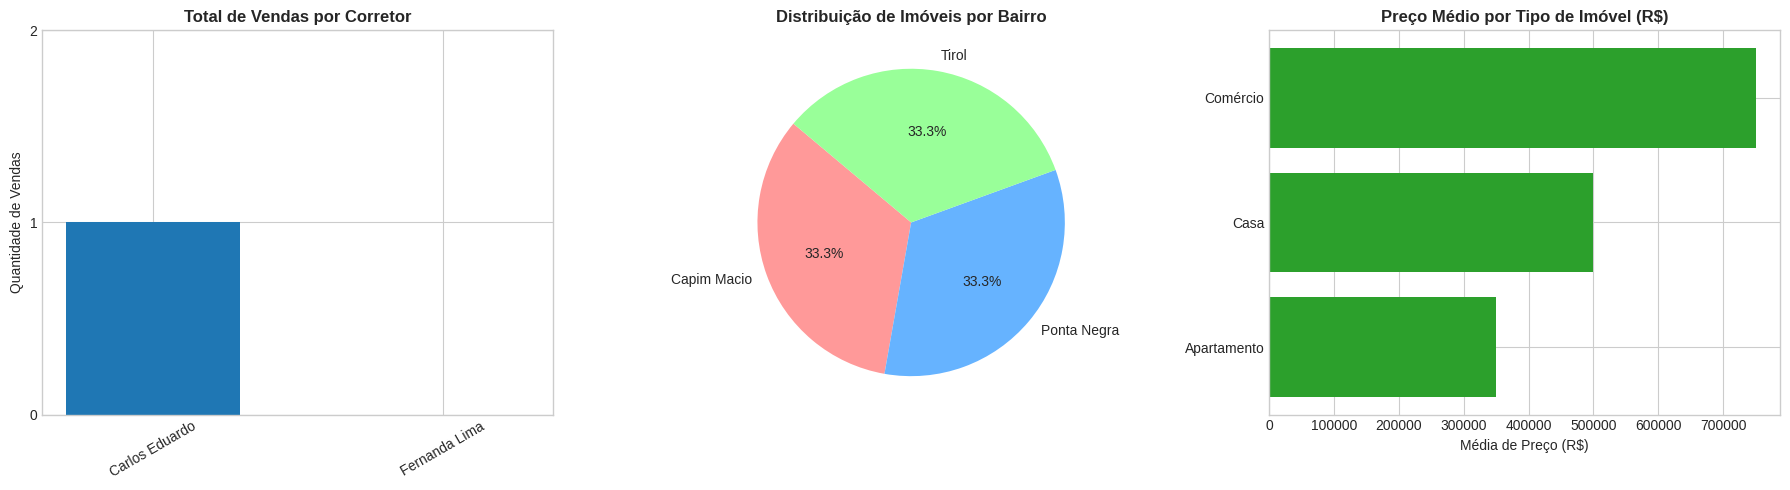

In [5]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Configuração visual dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# Conectando ao banco de dados
conn = sqlite3.connect('imobiliaria_pro.db')

# ----------------------------------------------------
# 1. Gráfico: Volume de Vendas por Corretor
# ----------------------------------------------------
query_vendas = """
    SELECT cor.nome AS corretor, COUNT(v.id_venda) AS total_vendas
    FROM Corretor cor
    LEFT JOIN Venda v ON cor.creci = v.creci_corretor
    GROUP BY cor.creci, cor.nome
"""
df_vendas = pd.read_sql_query(query_vendas, conn)

axes[0].bar(df_vendas['corretor'], df_vendas['total_vendas'], color='#1f77b4', width=0.6)
axes[0].set_title('Total de Vendas por Corretor', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Quantidade de Vendas')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_yticks(range(0, int(df_vendas['total_vendas'].max() + 2) if not df_vendas.empty else 2))

# ----------------------------------------------------
# 2. Gráfico: Quantidade de Imóveis por Bairro
# ----------------------------------------------------
query_bairros = """
    SELECT bairro, COUNT(*) AS quantidade
    FROM Imovel
    GROUP BY bairro
"""
df_bairros = pd.read_sql_query(query_bairros, conn)

axes[1].pie(
    df_bairros['quantidade'],
    labels=df_bairros['bairro'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#ff9999','#66b3ff','#99ff99','#ffcc99', '#c2c2f0']
)
axes[1].set_title('Distribuição de Imóveis por Bairro', fontsize=12, fontweight='bold')

# ----------------------------------------------------
# 3. Gráfico: Preço Médio por Tipo de Imóvel
# ----------------------------------------------------
query_precos = """
    SELECT tipo, AVG(preco) AS preco_medio
    FROM Imovel
    GROUP BY tipo
"""
df_precos = pd.read_sql_query(query_precos, conn)

axes[2].barh(df_precos['tipo'], df_precos['preco_medio'], color='#2ca02c')
axes[2].set_title('Preço Médio por Tipo de Imóvel (R$)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Média de Preço (R$)')

# Fechando a conexão
conn.close()

# Ajustando o layout e exibindo
plt.tight_layout()
plt.show()